In [ ]:
# 실습 준비 — 07주차 중간고사 범위 복습
# 이 셀을 먼저 한 번 실행하세요. 데이터가 없으면 아래 셀들이 전부 실패합니다.
import os, pathlib, urllib.request

BASE = "https://raw.githubusercontent.com/aprilslab/statistics-lab/main/data/"
FILES = []

pathlib.Path("data").mkdir(exist_ok=True)
for name in FILES:
    for dest in (pathlib.Path(name), pathlib.Path("data") / name):
        if not dest.exists():
            urllib.request.urlretrieve(BASE + name, dest)

# '../data/x.csv' 로 읽는 노트북 대응 — 상위 폴더에도 같은 data/ 를 걸어둔다.
# 절대경로(/data)로 박으면 cwd 가 /content 가 아닐 때 깨지므로 상대경로로 건다.
try:
    parent = pathlib.Path("..") / "data"
    if not parent.exists():
        os.symlink(pathlib.Path("data").resolve(), parent)
except OSError:
    pass

print("준비 완료:", ", ".join(FILES) if FILES else "(내려받을 데이터 없음)")


# 중간고사대비 연습문제

교재 01~06장 수업 노트북에서 쓰던 데이터·변수 이름·계산 코드를 모았습니다.
각 문제의 `{ }`를 채워 실행하세요. 각 장에서는 위에서부터 실행합니다.
준비 코드와 설명용 예제에는 실행 결과가 표시되어 있습니다.

- 준비 셀은 그대로 실행합니다. 데이터가 이 노트북에 들어 있어 Drive 연결이나 파일 업로드가 필요 없습니다.
- 각 문제에 원본 노트북과 셀 위치를 적었습니다. 막히면 해당 수업 코드를 다시 찾아보세요.
- 02장의 지표 계산은 앞 10명, 시각화는 50명 전체를 씁니다. 04장은 전교생 400명입니다.
- 06장 문제는 해당 수업을 들은 뒤 풉니다. 이 자료는 수업 코드 복습용이며 시험 문항 순서나 배점을 따르지 않습니다.
- 함수 도움말은 `np.mean?`, 자동완성은 Tab, 함수 인자 설명은 Shift + Tab으로 확인합니다.


In [1]:
# 공통 준비 — 가장 먼저 실행하세요
from io import StringIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

%precision 3
%matplotlib inline
pd.set_option('display.precision', 3)
np.set_printoptions(precision=3)


## A. 데이터 — 01장

표의 행은 관측 대상, 열은 변수입니다. `df.shape`는 `(행 수, 열 수)`, `df['열 이름']`은 해당 열의 값들을 반환합니다.

### 척도

| 척도 | 비교할 수 있는 것 | 예 |
|---|---|---|
| 명목 | 같은지 다른지 | 혈액형, 학과 코드 |
| 순서 | 높고 낮은 순서 | 만족도 등급 |
| 구간 | 값 사이의 차이 | 섭씨 온도, 연도 |
| 비율 | 차이와 배수 | 시간, 질량 |

구간척도의 0은 기준점입니다. 섭씨 20도는 10도보다 10도 높지만 두 배라고 하지는 않습니다. 비율척도의 0은 양이 없음을 뜻하므로 20분은 10분의 두 배입니다.

In [2]:
# 교재 데이터 — 실행하세요 (ch1_sport_test.csv)
df = pd.read_csv(StringIO('학생번호,학년,악력,윗몸일으키기,점수,순위\n1,1,40.2,34,15,4\n2,1,34.2,14,7,10\n3,1,28.8,27,11,7\n4,2,39.0,27,14,5\n5,2,50.9,32,17,2\n6,2,36.5,20,9,9\n7,3,36.6,31,13,6\n8,3,49.2,37,18,1\n9,3,26.0,28,10,8\n10,3,47.4,32,16,3\n'), index_col='학생번호')
df.head()

,학년,악력,윗몸일으키기,점수,순위
학생번호,,,,,
1,1,40.2,34,15,4
2,1,34.2,14,7,10
3,1,28.8,27,11,7
4,2,39.0,27,14,5
5,2,50.9,32,17,2


### A-1. 악력 열 꺼내기

수업 코드: `chap01_풀이.ipynb` · 데이터에 관하여 · 셀 4 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# A-1. 악력 열 꺼내기 — 원본 셀 4
# df에서 '악력' 열을 꺼내 출력하세요.
{ }

### A-2. 행과 열의 개수 확인하기

수업 코드: `chap01_풀이.ipynb` · 데이터에 관하여 · 셀 5 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# A-2. 행과 열의 개수 확인하기 — 원본 셀 5
# df의 (행 수, 열 수)를 확인하세요.
{ }

## B. 대푯값·산포도·표준화 — 02장

### 평균·중앙값·최빈값

- **평균**: 모든 값을 더해 개수로 나눈 값.
- **중앙값**: 정렬했을 때 가운데 값. 개수가 짝수면 가운데 두 값의 평균.
- **최빈값**: 가장 자주 나오는 값. 여러 개일 수 있음.

평균은 극단적인 값에 크게 영향을 받고, 중앙값은 상대적으로 영향을 덜 받습니다.

$$\bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_i$$

$x_i$는 i번째 값, $n$은 자료의 개수, $\bar{x}$는 평균입니다.

### 분산·표준편차

**편차** $x_i-\bar{x}$는 각 값에서 평균을 뺀 값입니다. 편차의 합은 0입니다. **분산**은 편차를 제곱한 값의 평균이고, **표준편차**는 분산의 제곱근입니다.

$$S^2=\frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{x})^2,\qquad S=\sqrt{S^2}$$

점수 자료라면 분산의 단위는 점², 표준편차의 단위는 점입니다. 이 연습에서는 n으로 나누는 분산을 씁니다. NumPy의 `var`·`std`는 기본 `ddof=0`으로 n으로 나누고, pandas는 기본 `ddof=1`로 n−1로 나눕니다.

### 범위·사분위범위

범위는 최댓값−최솟값입니다. $Q_1$은 25백분위수, $Q_2$는 중앙값, $Q_3$는 75백분위수입니다. **사분위범위**는 가운데 50%가 퍼진 폭입니다.

$$IQR=Q_3-Q_1$$

`np.percentile`은 값 사이를 보간하므로 사분위수가 소수로 나올 수 있습니다.

### 표준화·편차값

$$z_i=\frac{x_i-\bar{x}}{S}$$

표준화 점수 $z_i$는 평균에서 표준편차 몇 개만큼 떨어져 있는지 나타냅니다. $z=0$은 평균, $z=1$은 평균보다 표준편차 하나만큼 큰 값입니다. 표준화한 자료의 평균은 0, 표준편차는 1입니다. 단, $S=0$이면 정의되지 않습니다.

편차값 $50+10z_i$는 평균이 50, 표준편차가 10이 되도록 바꾼 값입니다.

In [5]:
# 교재 데이터 — 실행하세요 (ch2_scores_em.csv)
df = pd.read_csv(StringIO('student number,english,mathematics\n1,42,65\n2,69,80\n3,56,63\n4,41,63\n5,57,76\n6,48,60\n7,65,81\n8,49,66\n9,65,78\n10,58,82\n11,70,94\n12,47,75\n13,51,70\n14,64,77\n15,62,84\n16,70,84\n17,71,82\n18,68,85\n19,73,90\n20,37,70\n21,65,78\n22,65,93\n23,61,77\n24,52,88\n25,57,82\n26,57,76\n27,75,87\n28,61,84\n29,47,77\n30,54,82\n31,66,91\n32,54,75\n33,54,76\n34,42,78\n35,37,57\n36,79,89\n37,56,83\n38,62,69\n39,62,86\n40,55,81\n41,63,81\n42,57,80\n43,57,79\n44,67,87\n45,55,84\n46,45,71\n47,66,80\n48,55,77\n49,64,83\n50,66,88\n'), index_col='student number')
df.head()

,english,mathematics
student number,,
1,42,65
2,69,80
3,56,63
4,41,63
5,57,76


In [6]:
# 준비 — 실행하세요
# 영어점수를 numpy로 계산하기 위해 array 데이터 구조로 된 scores 라는 이름으로 저장합니다.
# 학생번호 10번까지만 잘라서 사용합니다.
scores = np.array(df['english'])[:10]
scores

# scores_df라는 이름으로 pandas의 DataFrame을 작성합니다.
# index로는 'student'라는 이름을 만들어 줍니다.
# ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J']

scores_df = pd.DataFrame({'score': scores}, index = pd.Index(['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J'], name='student'))
scores_df

,score
student,
A,42
B,69
C,56
D,41
E,57
F,48
G,65
H,49
I,65


### B-1. 합과 개수로 평균 구하기

수업 코드: `chap02_풀이.ipynb` · 평균값 (mean) · 셀 13 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# B-1. 합과 개수로 평균 구하기 — 원본 셀 13
# 평균값은 가장 잘 알려진 대푯값입니다.
# 평균값: (모든 데이터의 합) / (데이터의 개수)
# 합계를 구하는 함수: sum(np.array)
# 개수를 구하는 함수: len(np.array)

{ }

### B-2. NumPy로 평균과 중앙값 구하기

수업 코드: `chap02_풀이.ipynb` · 평균값 (mean) · 셀 14, 20 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# B-2. NumPy로 평균과 중앙값 구하기 — 원본 셀 14
# numpy 함수를 사용하여 구해봅니다.
{ }

In [ ]:
# B-2. NumPy로 평균과 중앙값 구하기 — 원본 셀 20
# numpy 의 median 함수를 사용하여 구해봅니다.
{ }

### B-3. 최빈값 구하기

수업 코드: `chap02_풀이.ipynb` · 최빈값 (mode) · 셀 23, 24 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# B-3. 최빈값 구하기 — 원본 셀 23
# 첫 셀 자료: [1, 1, 1, 2, 2, 3], 둘째 셀 자료: [1, 2, 3, 4, 5]. 각각 pd.Series로 만듭니다.
# 최빈값은 데이터에서 가장 많이 나타나는 값입니다.
# 최빈값은 기본적으로 질적 데이터의 대푯값을 구할 때 사용하는 지표입니다.
# 양적 데이터에서는 최빈값을 구하려고 해도 완전히 동일한 값이 나오는 경우가 거의 없기 때문입니다.
{ }

In [ ]:
# B-3. 최빈값 구하기 — 원본 셀 24
# 첫 셀 자료: [1, 1, 1, 2, 2, 3], 둘째 셀 자료: [1, 2, 3, 4, 5]. 각각 pd.Series로 만듭니다.
# pandas의 DataFrame이나 Series이 mode 함수로 구할 수 있습니다.
{ }

### B-4. 편차와 편차의 평균

수업 코드: `chap02_풀이.ipynb` · 편차 (deviation) · 셀 30, 32 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# B-4. 편차와 편차의 평균 — 원본 셀 30
# 사용할 변수 이름: mean, deviation
# numpy의 brodcast 기능을 이용해서 한번에 여러 편차를 구할 수 있습니다.
# 편차: (각 학생의 점수) - (평균)
mean = { }
deviation = { }
deviation

In [ ]:
# B-4. 편차와 편차의 평균 — 원본 셀 32
# numpy의 mean함수로 편차의 평균을 내봅시다.
{ }

### B-5. 편차의 제곱 평균과 분산 함수 비교

수업 코드: `chap02_풀이.ipynb` · 분산 (variance) · 셀 39, 40 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# B-5. 편차의 제곱 평균과 분산 함수 비교 — 원본 셀 39
# 산포도의 대푯값을 구할 때, 편차는 편차의 평균이 항상 0이기 때문에 사용할 수 없습니다.
# 흩어진 정도를 표기한다는 관점에서 -14점이나 +14점이나 동일한 산포도를 가지고 있습니다.
# 이처럼 산포도의 관점에서 -14점이나 +14점을 동일하게 취급하며 편차의 제곱을 이용합니다. 그리고 거기에 평균을 구한것이 '분산'입니다.
# 분산: 'deviation 제곱'의 평균

# python에서 제곱은 n ** 2로 구합니다.
# 분산을 구해봅시다.
{ }

In [ ]:
# B-5. 편차의 제곱 평균과 분산 함수 비교 — 원본 셀 40
# numpy의 var 함수로 구할 수 있습니다.
{ }

### B-6. 제곱근과 표준편차 함수 비교

수업 코드: `chap02_풀이.ipynb` · 표준편차 (standard deviation) · 셀 46, 47 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# B-6. 제곱근과 표준편차 함수 비교 — 원본 셀 46
# 표준편차는 numpy의 var 함수와 sqrt 함수를 사용하여 계산할 수 있습니다.
{ }

In [ ]:
# B-6. 제곱근과 표준편차 함수 비교 — 원본 셀 47
# numpy의 std 함수로 바로 구할 수도 있습니다.
{ }

### B-7. 범위와 사분위범위

수업 코드: `chap02_풀이.ipynb` · 범위 (range) · 셀 51, 54 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# B-7. 범위와 사분위범위 — 원본 셀 51
# numpy의 max 함수와 min 함수로 계산할 수 있습니다.
{ }

In [ ]:
# B-7. 범위와 사분위범위 — 원본 셀 54
# 사용할 변수 이름: scores_Q1, scores_Q3, scores_IQR
# numpy의 percentile 함수로 계산할 수 있습니다.
scores_Q1 = { }
scores_Q3 = { }
scores_IQR = { }
scores_IQR

### B-8. 표준화하고 평균·표준편차 확인

수업 코드: `chap02_풀이.ipynb` · 표준화 (standardization) · 셀 61, 62 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# B-8. 표준화하고 평균·표준편차 확인 — 원본 셀 61
# 사용할 변수 이름: z
# numpy의 mean함수, std함수로 z 점수를 계산할 수 있습니다.
z = { }
z

In [ ]:
# B-8. 표준화하고 평균·표준편차 확인 — 원본 셀 62
# 표준화된 데이터는 평균이 0, 표준편차가 1입니다.
# z 의 평균과 표준편차를 출력해봅시다.
{ }, { }

### B-9. 평균 50, 표준편차 10인 편차값

수업 코드: `chap02_풀이.ipynb` · 편차값 · 셀 65 (1부터 셈).

`{ }`를 채워 실행하세요.

이 셀은 `z`를 편차값으로 덮어씁니다. 표준화 점수를 다시 보려면 B-8부터 실행합니다.

In [ ]:
# B-9. 평균 50, 표준편차 10인 편차값 — 원본 셀 65
# 사용할 변수 이름: z
# numpy의 mean 함수, std 함수를 이용해서 평균이 50, 표준편차가 10인 편차값을 계산할 수 있습니다.
z = { }
z

## C. 도수분포·히스토그램·상자그림 — 02장

### 도수분포와 히스토그램

**도수**는 구간별 관측값의 개수, **상대도수**는 도수÷전체 개수입니다. **누적상대도수**는 낮은 구간부터 상대도수를 더한 값입니다.

히스토그램의 가로축은 값의 구간입니다. 세로축이 도수이고 구간 폭이 같으면 가장 높은 막대가 가장 많은 관측값을 포함한 구간입니다.

`bins=10, range=(0,100)`은 0~100을 폭 10인 구간 10개로 나눕니다. 왼쪽 경계는 포함하고 오른쪽 경계는 제외하되, 마지막 구간은 오른쪽 끝도 포함합니다. 10점은 10~20 구간에, 100점은 90~100 구간에 들어갑니다.

이 묶음에서는 영어 점수 50명 전체를 사용합니다.

In [23]:
# 준비 — 실행하세요
# 지금까지 데이터 요약을 통해 데이터의 특징을 파악해보았습니다.
# 이제는 표나 그림을 통해 시각화를 통해 데이터의 특징을 파악해봅시다.
# 50명의 영어 점수에 대한 array를 english_scores 라는 이름으로 작성하고

# pandas Series의 describe 함수로 주요 지표들을 확인해봅시다.
# 앞의 scores 는 앞 10명만 잘라 쓴 것입니다. 2.4 시각화부터는 50명 전체를 씁니다.
# 잘라내지 않으므로 [:10] 을 붙이지 않습니다 — count 가 50 으로 나와야 맞습니다.
english_scores = np.array(df['english'])
pd.Series(english_scores).describe()

count    50.00
mean     58.38
std       9.80
min      37.00
25%      54.00
50%      57.50
75%      65.00
max      79.00
dtype: float64

### C-1. 10점 간격 도수와 상대도수

수업 코드: `chap02_풀이.ipynb` · 도수분포표 (frequency distribution table) · 셀 70, 73, 74 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# C-1. 10점 간격 도수와 상대도수 — 원본 셀 70
# 사용할 변수 이름: freq
# 데이터의 분포상태를 알고 싶을 때, 데이터를 몇개의 구간으로 나누고, 각 구간에 몇 개의 데이터가 들어가는 지 세는 방법이 있습니다.
# 이처럼 분할된 구간과 데이터의 개수를 표로 정리한 것이 '도수분포표'입니다.
# 예) 시험점수를 10점 간격으로 나누어 도수분포표를 작성한다 했을 때,
#    - 계급(class): 각 구간 (0~10,10~20, ... , 90~100)
#    - 도수(frequency): 각 계급에 속한 학생 수
#    - 계급폭: 각 구만의 폭 (10)
#    - 계급수: 총 계급의 수 (100점을 폭 10 단위로 나누면 계급수는 100/10 = 10)
#    - 계급값: 각 계급을 대표하는 값
#    - 상대도수: 전체 데이터에서 해당 계급의 데이터가 어느정도의 비율을 차지하고 있는지
#    - 누적상대도수: 해당 계급까지의 상대도수의 합

# numpy의 histogram 함수로 도수를 계산할 수 있습니다.
# bins=10: 계급수 10개, range=(0,100): 0점부터 100점까지를 그 10개로 나눈다
# 시각화 절이므로 10명(scores)이 아니라 50명 전체(english_scores)를 씁니다.
freq, _ = { }
freq

In [ ]:
# C-1. 10점 간격 도수와 상대도수 — 원본 셀 73
# 사용할 변수 이름: rel_freq
# 상대도수는 도수에서 도수의 합을 나눠서 계산할 수 있습니다.
rel_freq = { }
rel_freq

In [ ]:
# C-1. 10점 간격 도수와 상대도수 — 원본 셀 74
# 사용할 변수 이름: cum_rel_freq
# 누적상대도수는 numpy의 cumsum 함수로 계산할 수 있습니다.
cum_rel_freq = { }
cum_rel_freq

### C-2. 히스토그램 직접 그리기

수업 코드: `chap02_풀이.ipynb` · 히스토그램 (histogram) · 셀 80 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# C-2. 히스토그램 직접 그리기 — 원본 셀 80
# 사용할 변수 이름: fig, ax, freq
# 캔버스를 생성
# figsize로 가로・세로 크기를 지정
fig = plt.figure(figsize=(10, 6))
# 켄버스 위에 그래프를 그리기 위한 영역을 지정
# 인수는 영역을 1×1개 지정、하나의 영역에 그린다는 것을 의미
ax = fig.add_subplot(111)

# 계급수를 10으로 하여 히스토그램을 그림
freq, _, _ = { }
# X축에 레이블 부여
ax.set_xlabel('score')
# Y축에 레이블 부여
ax.set_ylabel('person number')
# X축을 0, 10, 20, ..., 100 눈금으로 구분
ax.set_xticks(np.linspace(0, 100, 10+1))
# Y축을 0, 1, 2, ...의 눈금으로 구분
ax.set_yticks(np.arange(0, freq.max()+1))
# 그래프 표시
plt.show()

### 상자그림

| 그림의 부분 | 의미 |
|---|---|
| 상자 아래·위 경계 | $Q_1$, $Q_3$ |
| 상자 안의 가로선 | 중앙값 $Q_2$ |
| 상자의 높이 | 사분위범위 $IQR$ |
| 아래·위 수염 끝 | $Q_1-1.5IQR$~$Q_3+1.5IQR$ 안에 있는 관측값 중 최솟값·최댓값 |
| 수염 밖의 개별 점 | 이 기준에서 벗어난 이상값 후보 |

아래 셀은 각 부분의 이름이 붙은 상자그림을 그립니다. `Median (Q2)`는 중앙값, `Lower/Upper whisker`는 아래·위 수염입니다. 파란 화살표는 IQR, `Outside whiskers`는 수염 밖의 점을 가리킵니다.

예시 자료는 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 20입니다. 중앙값은 7, $Q_1$은 4.5, $Q_3$는 9.5, IQR은 5입니다. 수염의 기준 범위는 −3~17이고, 실제 수염은 그 안의 관측값인 2와 11에서 끝납니다. 20은 별도의 점으로 표시됩니다. 점선은 기준 범위의 위쪽 끝인 17입니다.

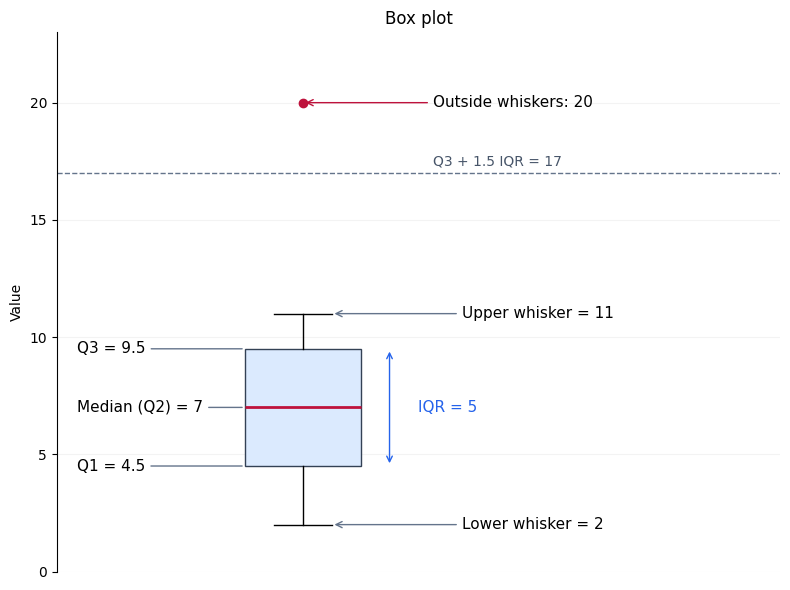

In [28]:
%matplotlib inline
# 상자그림 예시 — 그대로 실행하면 그림이 표시됩니다.
import numpy as np
import matplotlib.pyplot as plt

boxplot_data = np.array([2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 20])
box_q1, box_median, box_q3 = np.percentile(boxplot_data, [25, 50, 75])
box_iqr = box_q3 - box_q1
box_low = box_q1 - 1.5 * box_iqr
box_high = box_q3 + 1.5 * box_iqr
box_inside = boxplot_data[(boxplot_data >= box_low) & (boxplot_data <= box_high)]

fig, ax = plt.subplots(figsize=(8, 6))
ax.boxplot(boxplot_data, widths=0.4, patch_artist=True,
           boxprops={'facecolor': '#dbeafe', 'edgecolor': '#334155'},
           medianprops={'color': '#be123c', 'linewidth': 2},
           flierprops={'marker': 'o', 'markerfacecolor': '#be123c',
                       'markeredgecolor': '#be123c'})
for label, value in [('Q1', box_q1), ('Median (Q2)', box_median), ('Q3', box_q3)]:
    ax.annotate(f'{label} = {value:g}', xy=(0.8, value), xytext=(0.22, value),
                va='center', fontsize=11,
                arrowprops={'arrowstyle': '-', 'color': '#64748b'})
for label, value in [('Lower whisker', box_inside.min()), ('Upper whisker', box_inside.max())]:
    ax.annotate(f'{label} = {value:g}', xy=(1.1, value), xytext=(1.55, value),
                va='center', fontsize=11,
                arrowprops={'arrowstyle': '->', 'color': '#64748b'})
ax.annotate('Outside whiskers: 20', xy=(1, 20), xytext=(1.45, 20),
            va='center', fontsize=11,
            arrowprops={'arrowstyle': '->', 'color': '#be123c'})
ax.annotate('', xy=(1.3, box_q1), xytext=(1.3, box_q3),
            arrowprops={'arrowstyle': '<->', 'color': '#2563eb'})
ax.text(1.4, box_median, f'IQR = {box_iqr:g}', va='center', color='#2563eb', fontsize=11)
ax.axhline(box_high, color='#64748b', linestyle='--', linewidth=1)
ax.text(1.45, box_high + 0.3, f'Q3 + 1.5 IQR = {box_high:g}', color='#475569', fontsize=10)
ax.set(xlim=(0.15, 2.65), ylim=(0, 23), xticks=[], ylabel='Value', title='Box plot')
ax.spines[['top', 'right', 'bottom']].set_visible(False)
ax.yaxis.grid(True, alpha=0.15)
fig.tight_layout()
plt.show()


## D. 공분산·상관계수 — 03장

`df['열']`은 열을, `df.loc['행', '열']`은 레이블로 지정한 값을 꺼냅니다. `loc['A':'D']`는 D도 포함하고, 정수 위치로 고르는 `iloc`의 슬라이스는 끝 위치를 제외합니다.

### 공분산

공분산은 두 변수의 편차를 곱한 값의 평균입니다.

$$S_{xy}=\frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})$$

두 값이 각자의 평균보다 함께 크거나 함께 작으면 편차의 곱은 양수입니다. 한쪽은 크고 다른 쪽은 작으면 음수입니다. 공분산의 부호는 관계의 방향을 나타내며, 크기는 변수의 단위에 영향을 받습니다.

### 상관계수와 산점도

상관계수는 공분산을 두 표준편차의 곱으로 나눈 값입니다.

$$r_{xy}=\frac{S_{xy}}{S_xS_y}$$

상관계수는 −1~1 사이입니다. 1에 가까우면 강한 양의 선형 관계, −1에 가까우면 강한 음의 선형 관계, 0에 가까우면 선형 관계가 약합니다. 어느 한 변수의 표준편차가 0이면 정의되지 않습니다.

산점도에서 점 하나는 한 관측 대상의 두 변수 값을 나타냅니다. 점들이 오른쪽 위로 향하면 양의 관계, 오른쪽 아래로 향하면 음의 관계입니다. 곡선 관계는 상관계수가 0에 가까워도 나타날 수 있습니다. 상관관계만으로 인과관계를 알 수는 없습니다.

`np.cov`와 `np.corrcoef`는 행렬을 반환합니다. 두 변수 사이의 값은 `[0, 1]` 또는 `[1, 0]`입니다. 공분산 행렬의 대각선은 각 변수의 분산입니다.

In [29]:
# 교재 데이터 — 실행하세요 (ch2_scores_em.csv)
df = pd.read_csv(StringIO('student number,english,mathematics\n1,42,65\n2,69,80\n3,56,63\n4,41,63\n5,57,76\n6,48,60\n7,65,81\n8,49,66\n9,65,78\n10,58,82\n11,70,94\n12,47,75\n13,51,70\n14,64,77\n15,62,84\n16,70,84\n17,71,82\n18,68,85\n19,73,90\n20,37,70\n21,65,78\n22,65,93\n23,61,77\n24,52,88\n25,57,82\n26,57,76\n27,75,87\n28,61,84\n29,47,77\n30,54,82\n31,66,91\n32,54,75\n33,54,76\n34,42,78\n35,37,57\n36,79,89\n37,56,83\n38,62,69\n39,62,86\n40,55,81\n41,63,81\n42,57,80\n43,57,79\n44,67,87\n45,55,84\n46,45,71\n47,66,80\n48,55,77\n49,64,83\n50,66,88\n'), index_col='student number')
df.head()

,english,mathematics
student number,,
1,42,65
2,69,80
3,56,63
4,41,63
5,57,76


In [30]:
# 준비 — 실행하세요
# DataFrame에서 df['column이름']을 입력하면 해당 컬럼을 Series로 리턴합니다.
# 'english', 'mathematics' 열의 Series를 입력받아 numpy array를 생성하고, 10개의 행을 index slice 해줍니다.
en_scores = np.array(df['english'])[:10]
ma_scores = np.array(df['mathematics'])[:10]

# index 생성은 index=pd.Index({lables list}, name='{인덱스 이름}') << 형식으로 생성해줍니다. rows의 갯수와 같아야합니다.
# 레이블은 ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J'] 로 이름은 'student' 인덱스를 생성합니다.

scores_df = pd.DataFrame({'english':en_scores, 'mathematics':ma_scores}, index=pd.Index(['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J'], name='student'))

# DataFrame을 전체 출력해봅시다.
scores_df

,english,mathematics
student,,
A,42,65
B,69,80
C,56,63
D,41,63
E,57,76
F,48,60
G,65,81
H,49,66
I,65,78


### D-1. 레이블로 행·열 선택하기

수업 코드: `chap03_풀이.ipynb` · * 레이블을 통한 데이터 접근: df.loc · 셀 25, 29 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# D-1. 레이블로 행·열 선택하기 — 원본 셀 25
# 'B'행의 'mathematics' 점수를 가져와 봅시다.
{ }

In [ ]:
# D-1. 레이블로 행·열 선택하기 — 원본 셀 29
# 'A' ~ 'D' 행 까지의 mathematics 열을 가져와 봅시다.
{ }

### 평균선을 넣은 산점도

빨간 세로선은 영어 평균, 파란 가로선은 수학 평균입니다. +와 −는 두 편차의 곱의 부호입니다.

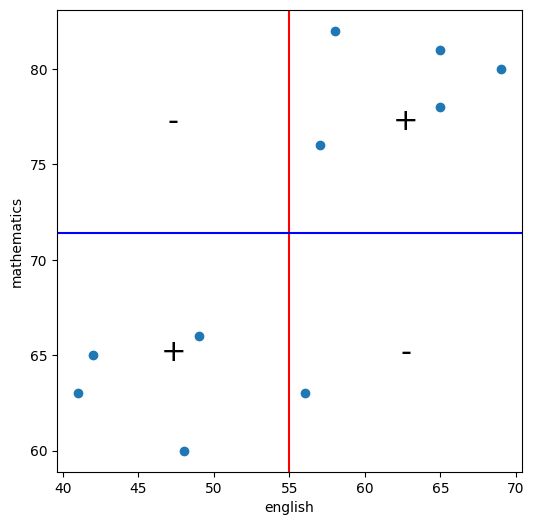

In [33]:
# X, Y라는 특성이 있을 때, X가 높을 수록 Y도 높은 경향이 있다 → 양의 상관관계
# X, Y라는 특성이 있을 때, X가 높을 수록 Y가 낮은 경향이 있다 → 음의 상관관계
# X, Y라는 특성이 있을 때, 양의 상관관계도 아니고 음의 상관관계도 아니다 → 무상관

# 영어와 수학점수가 어떻게 분포되어 있는지 살표봅시다.
# 빨간 선은 영어점수의 평균, 파란선은 수학점수의 평균입니다.
# 점수의 분포를 살펴보면 영어점수와 수학점수는 양의 상관관계에 있다고 말할 수 있습니다.
# 이처럼, 상관관계가 있다고 생각되는 데이터의 관계성을 수치화할 때 사용하는 지표가 공분산(covariance)입니다.

# 시각화를 할때 사용하는 패키지를 import 합니다.
import matplotlib.pyplot as plt

# 그림판 만들기
fig = plt.figure(figsize=(6,6))
ax = fig.add_subplot(111)

# 산점도 그리기
ax.scatter(en_scores, ma_scores)

# 평균 선 그어주기
ax.axvline(en_scores.mean(), color='red')
ax.axhline(ma_scores.mean(), color='blue')

ax.set_xlabel('english')
ax.set_ylabel('mathematics')
plot_xmin, plot_xmax = ax.get_xlim()
plot_ymin, plot_ymax = ax.get_ylim()
for plot_x, plot_y, sign in [
    ((plot_xmin + en_scores.mean()) / 2, (plot_ymin + ma_scores.mean()) / 2, '+'),
    ((plot_xmax + en_scores.mean()) / 2, (plot_ymax + ma_scores.mean()) / 2, '+'),
    ((plot_xmin + en_scores.mean()) / 2, (plot_ymax + ma_scores.mean()) / 2, '-'),
    ((plot_xmax + en_scores.mean()) / 2, (plot_ymin + ma_scores.mean()) / 2, '-'),
]:
    ax.text(plot_x, plot_y, sign, fontsize=22, ha='center', va='center',
            bbox={'facecolor': 'white', 'alpha': 0.8, 'edgecolor': 'none'})
plt.show()

### D-2. 편차의 곱으로 공분산 구하기

수업 코드: `chap03_풀이.ipynb` · 공분산(共分散) · 셀 49, 50 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# D-2. 편차의 곱으로 공분산 구하기 — 원본 셀 49
# 사용할 변수 이름: summary_df
# DataFrame을 사용해서 수치를 정리해봅시다.
summary_df = scores_df.copy()
summary_df['english_deviation'] = { }
summary_df['mathematics_deviation'] = { }
summary_df['product of deviations'] = { }
summary_df

In [ ]:
# D-2. 편차의 곱으로 공분산 구하기 — 원본 셀 50
# 자신과 상대방의 편차의 곱을 만들었으니 평균을 구하면 공분산이 구해집니다.
{ }

### D-3. 공분산 행렬에서 공분산 꺼내기

수업 코드: `chap03_풀이.ipynb` · 공분산(共分散) · 셀 51, 54 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# D-3. 공분산 행렬에서 공분산 꺼내기 — 원본 셀 51
# 사용할 변수 이름: cov_mat
# numpy에서는 cov함수를 제공합니다.
# 반환값은 공분산값인 Scalar 형태가 아니라 2차원 배열(행렬)입니다.
# 0번째 인자값과 1번째 인자값의 곱셈에 대한 경우의 수 만큼의 갯수를 반환합니다.
#[(0,0),(0,1)]
#[(1,0),(1,1)]
cov_mat = { }
cov_mat

In [ ]:
# D-3. 공분산 행렬에서 공분산 꺼내기 — 원본 셀 54
# [0,1] 성분은 (영어편차 X 수학편차) 합계의 평균
# [1,0] 성분은 (수학편차 X 영어편차) 합계의 평균
# 같은 값이고, 공분산입니다.
{ }

### 상관계수와 점의 분포

각 제목의 r은 자료를 생성할 때 지정한 상관계수입니다. 표본에서 계산한 상관계수는 조금 다를 수 있습니다.

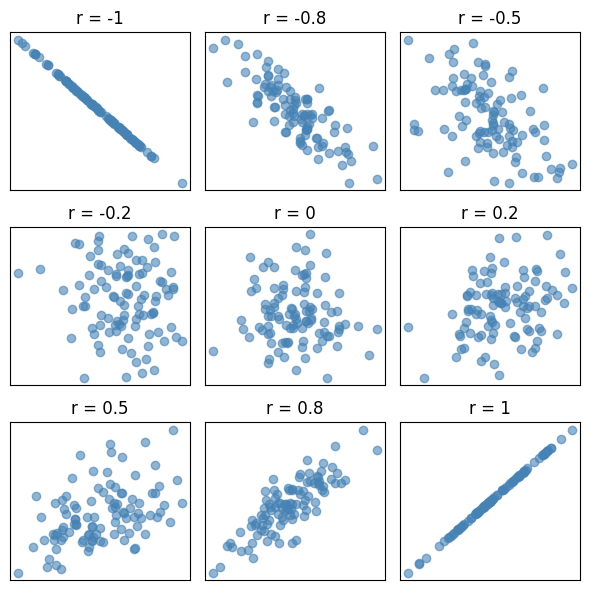

In [38]:
# 준비 — 실행하세요
# 다음은 몇가지 상관계수에 대응하는 산점도입니다.

import numpy as np
import matplotlib.pyplot as plt

# 랜덤 시드 고정
np.random.seed(0)

# 원하는 상관계수 값들
r_values = [-1, -0.8, -0.5, -0.2, 0, 0.2, 0.5, 0.8, 1]

# 데이터 개수
n = 100

# 3x3 subplot 준비
fig = plt.figure(figsize=(6, 6))

for i, r in enumerate(r_values):
    # 공분산 행렬 구성
    cov = [[1, r],
           [r, 1]]

    # 다변량 정규분포 샘플 생성 (평균 0, 분산 1, 상관 r)
    data = np.random.multivariate_normal([0, 0], cov, size=n)
    x, y = data.T

    ax = fig.add_subplot(3, 3, i+1)
    ax.scatter(x, y, alpha=0.6, color="steelblue")
    ax.set_title(f"r = {r}")
    ax.set_xticks([])
    ax.set_yticks([])


plt.tight_layout()
plt.show()

### D-4. 공분산으로 구한 상관계수와 함수 비교

수업 코드: `chap03_풀이.ipynb` · 상관계수 · 셀 61, 62 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# D-4. 공분산으로 구한 상관계수와 함수 비교 — 원본 셀 61
# p.77에서 상관계수와 관련된 산점도를 확인할 수 있습니다.
# 영어점수와 수학점수의 상관계수를 계산해봅시다.
{ }

In [ ]:
# D-4. 공분산으로 구한 상관계수와 함수 비교 — 원본 셀 62
# numpy에서는 corrcoef함수를 제공합니다.
# correlation(상관관계) + coefficient(계수)
# 반환값은 cov와 마찬가지로 Scalar가 아니라 행렬입니다. (상관행렬)
{ }

### D-5. 50명의 산점도 그리기

수업 코드: `chap03_풀이.ipynb` · 산점도 · 셀 67 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# D-5. 50명의 산점도 그리기 — 원본 셀 67
# 사용할 변수 이름: english_scores, math_scores, fig, ax
# 이번에는 10개 데이터 뿐만 아니라, 전체데이터를 시각화해봅시다.
# 위의 산점도 중 r=0.8의 산점도와 상당히 비슷한 모습을 확인할 수 있습니다.

english_scores = np.array(df['english'])
math_scores = np.array(df['mathematics'])

# 그림판 준비하기.
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111)

# 산점도 그리기
{ }

ax.set_xlabel('english')
ax.set_ylabel('mathematics')

# 산점도 보여주기
plt.show()

## E. 표본 추출 — 04장

**모집단**은 알고 싶은 대상 전체, **표본**은 그중 실제로 뽑아 조사한 일부입니다. 모집단의 평균 같은 특성값은 **모수**, 표본에서 계산한 평균 같은 값은 **통계량**입니다.

도서관 이용자 전체의 평균 방문 시간을 알아보려고 일부 이용자를 조사했다면, 전체 이용자가 모집단이고 조사한 사람들이 표본입니다. 표본평균은 추출할 때마다 달라질 수 있습니다.

| 추출 방식 | 뽑은 뒤 처리 | 같은 대상의 재추출 | 코드 |
|---|---|---|---|
| 복원추출 | 되돌려 놓음 | 가능 | `replace=True` (기본값) |
| 비복원추출 | 되돌려 놓지 않음 | 불가능 | `replace=False` |

비복원추출에서도 서로 다른 학생의 점수가 같으면 같은 숫자가 여러 번 나올 수 있습니다. 표본 크기는 모집단 크기를 넘을 수 없습니다.

`np.random.seed`는 난수 추출 결과를 재현하기 위한 설정입니다. 조사하기 편한 사람만 고르는 등 선택 방식이 한쪽에 치우치면 **선택 편향**이 생깁니다.

In [42]:
# 교재 데이터 — 실행하세요 (ch4_scores400.csv)
df = pd.read_csv(StringIO('score\n76\n55\n80\n80\n74\n61\n81\n76\n23\n80\n41\n80\n68\n88\n69\n57\n68\n86\n70\n68\n81\n73\n70\n90\n93\n79\n66\n92\n88\n81\n52\n72\n59\n68\n74\n72\n63\n89\n45\n81\n42\n76\n57\n83\n71\n74\n55\n60\n73\n79\n100\n73\n85\n47\n50\n65\n52\n92\n64\n91\n92\n71\n78\n69\n78\n77\n68\n78\n96\n81\n75\n72\n55\n55\n75\n49\n59\n89\n99\n45\n94\n67\n70\n68\n86\n46\n77\n56\n79\n93\n70\n76\n76\n58\n93\n96\n81\n71\n63\n61\n96\n91\n69\n46\n28\n54\n68\n91\n60\n78\n90\n72\n68\n50\n52\n76\n67\n72\n69\n80\n58\n65\n98\n58\n66\n61\n77\n85\n63\n64\n66\n78\n59\n64\n34\n49\n68\n83\n74\n54\n49\n73\n45\n86\n71\n46\n56\n59\n58\n48\n57\n60\n59\n87\n72\n55\n65\n57\n65\n83\n74\n100\n76\n56\n82\n86\n86\n54\n68\n87\n45\n63\n49\n56\n55\n89\n66\n57\n54\n72\n70\n90\n78\n49\n61\n86\n61\n96\n54\n79\n57\n62\n86\n68\n82\n77\n81\n57\n67\n76\n57\n94\n58\n65\n55\n38\n97\n67\n63\n67\n91\n56\n80\n64\n61\n79\n85\n62\n58\n52\n87\n61\n42\n91\n49\n82\n73\n74\n61\n75\n45\n79\n93\n83\n40\n55\n67\n77\n68\n63\n79\n87\n67\n81\n31\n56\n65\n63\n75\n85\n78\n61\n47\n78\n42\n80\n67\n52\n74\n70\n69\n69\n76\n84\n77\n85\n69\n94\n79\n62\n54\n73\n50\n55\n74\n61\n56\n69\n71\n67\n64\n83\n75\n67\n100\n73\n87\n62\n50\n58\n66\n63\n90\n68\n77\n69\n63\n71\n96\n58\n82\n55\n63\n70\n75\n92\n69\n57\n80\n65\n74\n68\n41\n78\n79\n84\n97\n52\n78\n76\n64\n76\n77\n52\n74\n56\n60\n43\n63\n67\n78\n70\n47\n83\n68\n77\n84\n91\n99\n69\n75\n54\n86\n52\n43\n82\n62\n82\n76\n46\n29\n54\n70\n52\n60\n48\n73\n71\n63\n91\n92\n78\n43\n53\n76\n61\n63\n83\n78\n90\n64\n91\n62\n92\n72\n57\n46\n65\n66\n83\n68\n64\n86\n67\n61\n79\n63\n80\n61\n67\n72\n64\n70\n82\n76\n77\n60\n83\n80\n85\n'))
df.head()

,score
0,76
1,55
2,80
3,80
4,74


In [43]:
# 04장 준비 — 전교생 400명의 점수
scores = np.array(df['score'])
np.random.seed(0)

### E-1. 복원추출과 비복원추출

수업 코드: `chap04_풀이.ipynb` · 표본의 추출방법 · 셀 12, 13 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# E-1. 복원추출과 비복원추출 — 원본 셀 12
# [1, 2, 3]에서 3개를 뽑습니다. 첫 셀은 복원추출, 둘째 셀은 비복원추출입니다.
# - 무작위추출(random sampling): 임의로 표본을 추출하는 방법
# 편향없는 표본 추출을 위함입니다.
# 셀을 실행 할 때 마다 결과가 달라집니다.
# 동일한 숫자가 여러번 추출되는 경우가 있습니다. >> '복원추출(sampling with replacement)'

# 셀을 여러번 실행해봅시다. (ctrl + Enter) 연타!!

{ }

In [ ]:
# E-1. 복원추출과 비복원추출 — 원본 셀 13
# [1, 2, 3]에서 3개를 뽑습니다. 첫 셀은 복원추출, 둘째 셀은 비복원추출입니다.
# 동일한 숫자가 여러번 추출안되게, 즉, '비복원추출(sampling without replacement)' 하려면?
# np.random.choice 인수 replace를 False로 합니다.

# 셀을 여러번 실행해봅시다. (ctrl + Enter) 연타!!

{ }

### E-2. 시드를 고정해 20명 뽑기

수업 코드: `chap04_풀이.ipynb` · 표본의 추출방법 · 셀 16 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# E-2. 시드를 고정해 20명 뽑기 — 원본 셀 16
# 사용할 변수 이름: sample
# 난수시드를 설정하고 표본 크기가 20인 표본을 추출해봅시다
np.random.seed(0)
sample = { }

### E-3. 표본평균과 모평균 비교

수업 코드: `chap04_풀이.ipynb` · 표본의 추출방법 · 셀 17, 18 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# E-3. 표본평균과 모평균 비교 — 원본 셀 17
# 해당 표본의 표본평균을 구해봅시다.
{ }

In [ ]:
# E-3. 표본평균과 모평균 비교 — 원본 셀 18
# 우리는 전교생의 점수도 갖고 있기 때문에 모평균도 구할 수 있습니다.
# 모평균을 구해봅시다.
{ }

## F. 확률함수·기댓값·분산 — 05장

### 확률표

**X**는 관찰 결과를 숫자로 나타낸 확률변수, **x**는 X가 가질 수 있는 구체적인 값입니다. **P**는 확률을 뜻하므로 $P(X=x)$는 “X의 값이 x일 확률”이라고 읽습니다.

한 봉지에 들어 있는 사탕 수 X가 2, 4, 6 중 하나라면 다음과 같이 나타낼 수 있습니다.

| $x$ — 사탕 수(개) | 2 | 4 | 6 |
|---|---|---|---|
| $P(X=x)$ — 그 수가 들어 있을 확률 | 0.15 | 0.55 | 0.30 |

윗줄은 사탕 수, 아랫줄은 확률입니다. $P(X=4)=0.55$는 사탕이 4개일 확률이 55%라는 뜻입니다. 가능한 경우 전체의 확률을 더하면 $0.15+0.55+0.30=1$, 즉 100%입니다.

확률함수 $f(x)=P(X=x)$는 각 값의 확률을 나타냅니다.

$$f(x)\geq 0,\qquad \sum_x f(x)=1$$

수업 코드의 `x_set`은 가능한 값, `prob`는 그 값들의 확률입니다. 두 배열에서 같은 위치끼리 한 쌍입니다. `X = [x_set, f]`는 수업에서 만든 함수 `E`와 `V`에 분포 정보를 전달하는 묶음입니다.

아래 그림은 위 사탕 표를 막대로 나타낸 것입니다. 가로축은 사탕 수 x, 막대의 높이는 확률 P(X=x)입니다.

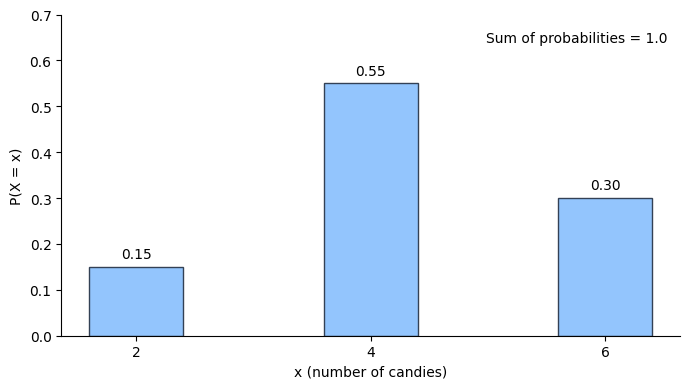

In [49]:
%matplotlib inline
# 확률표의 사탕 수와 확률 — 그대로 실행하세요.
import numpy as np
import matplotlib.pyplot as plt

candy_values = np.array([2, 4, 6])
candy_prob = np.array([0.15, 0.55, 0.30])
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(candy_values, candy_prob, width=0.8, color='#93c5fd', edgecolor='#334155')
ax.bar_label(bars, labels=[f'{p:.2f}' for p in candy_prob], padding=4)
ax.set(xlabel='x (number of candies)', ylabel='P(X = x)', xticks=candy_values, ylim=(0, 0.7))
ax.text(0.98, 0.95, f'Sum of probabilities = {candy_prob.sum():.1f}',
        transform=ax.transAxes, ha='right', va='top')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()


### 기댓값·분산

**기댓값**은 각 값에 그 값의 확률을 곱해 더한 평균입니다. $E(X)$ 또는 $\mu$로 씁니다.

$$\mu=E(X)=\sum_x x f(x)$$

**분산**은 기댓값에서 떨어진 거리를 제곱한 값에 확률을 곱해 더한 값입니다.

$$V(X)=\sum_x (x-\mu)^2 f(x)$$

`np.var(x_set)`은 모든 값의 비중을 같게 취급합니다. 각 값의 확률이 다를 때는 위 식처럼 확률을 반영합니다.

### 값의 변환

$$E(aX+b)=aE(X)+b,\qquad V(aX+b)=a^2V(X)$$

b를 더하면 중심만 이동하고 흩어진 정도는 그대로입니다. a배하면 거리의 제곱은 a²배가 되므로 분산도 a²배가 됩니다.

수업 함수의 `g`는 X의 값을 바꾸는 함수입니다. `lambda x: 2*x + 3`은 x를 받아 2x+3을 반환합니다.

다음 F-1~F-5는 수업에서 다룬 주사위입니다. 눈은 1~6이고 각 눈 x의 확률은 x/21입니다.

In [50]:
# 준비 — 실행하세요
# 1) 확률변수 X의 가능한 값 정의
x_set = np.array([1, 2, 3, 4, 5, 6])

# 2) 확률함수 정의
def f(x):
    if x in x_set:
        return x / 21
    else:
        return 0

X=[x_set, f]

### F-1. 확률 배열과 확률의 조건 확인

수업 코드: `chap05_풀이.ipynb` · 1차원 이산확률분포의 정의 · 셀 8, 10, 11 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# F-1. 확률 배열과 확률의 조건 확인 — 원본 셀 8
# 사용할 변수 이름: prob, x_k
# 확률 p_k를 구한다
prob = { }

In [ ]:
# F-1. 확률 배열과 확률의 조건 확인 — 원본 셀 10
# 4) 확률이 0이상인지 검증
{ }

In [ ]:
# F-1. 확률 배열과 확률의 조건 확인 — 원본 셀 11
# 5) 확률 합이 1인지 검증
{ }

### F-2. 값 × 확률의 합으로 기댓값 계산

수업 코드: `chap05_풀이.ipynb` · 평균 (기댓값: Expected value) · 셀 23 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# F-2. 값 × 확률의 합으로 기댓값 계산 — 원본 셀 23
# 사용할 변수 이름: x_k
{ }

In [55]:
# 준비 — 실행하세요
def E(X, g=lambda x: x):
    x_set, f = X
    return np.sum([g(x_k) * f(x_k) for x_k in x_set])

### F-3. E(2X+3)를 두 방법으로 계산

수업 코드: `chap05_풀이.ipynb` · 기댓값의 선형성 · 셀 28, 29 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# F-3. E(2X+3)를 두 방법으로 계산 — 원본 셀 28
{ }

In [ ]:
# F-3. E(2X+3)를 두 방법으로 계산 — 원본 셀 29
{ }

### F-4. 기댓값을 사용해 분산 계산

수업 코드: `chap05_풀이.ipynb` · 분산 · 셀 31 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# F-4. 기댓값을 사용해 분산 계산 — 원본 셀 31
# 사용할 변수 이름: mean, x_k
mean = { }
{ }

In [59]:
# 준비 — 실행하세요
# 인수가 g인 확률변수
def V(X, g=lambda x: x):
    x_set, f = X
    mean = E(X, g)
    return np.sum([(g(x_k)-mean)**2 * f(x_k) for x_k in x_set])

### F-5. V(2X+3)를 두 방법으로 계산

수업 코드: `chap05_풀이.ipynb` · 분산 · 셀 35, 37 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# F-5. V(2X+3)를 두 방법으로 계산 — 원본 셀 35
# g를 지정함
{ }

In [ ]:
# F-5. V(2X+3)를 두 방법으로 계산 — 원본 셀 37
{ }

## G. 대표적인 이산형 확률분포 — 06장

| 분포 | X의 의미 | 가능한 값 | 기댓값 | 분산 |
|---|---|---|---|---|
| 베르누이 | 한 번 시행의 성공 여부 | 0, 1 | $p$ | $p(1-p)$ |
| 이항 | n번 시행에서 성공한 횟수 | 0~n의 정수 | $np$ | $np(1-p)$ |
| 기하 | 첫 성공까지 시행한 횟수 | 1, 2, 3, … | $1/p$ | $(1-p)/p^2$ |
| 포아송 | 일정 시간·공간 구간의 사건 수 | 0, 1, 2, … | $\lambda$ | $\lambda$ |

이항·기하분포는 시행들이 독립이고 성공 확률 p가 일정한 상황에 씁니다. 기하분포는 성공한 시행까지 포함해 횟수를 셉니다. 첫 시행에 성공하면 X=1이며, p는 0보다 커야 합니다.

포아송분포는 발생률이 일정하고 겹치지 않는 구간의 사건 수가 독립인 모형입니다. λ는 해당 구간의 평균 횟수입니다. 시간당 평균이 2회라면 같은 발생률에서 3시간의 평균은 6회입니다.

### SciPy 표기

`stats.bernoulli(p)`, `stats.binom(n, p)`, `stats.geom(p)`, `stats.poisson(lam)`은 각 분포의 객체를 만듭니다.

| 메서드 | 의미 |
|---|---|
| `rv.pmf(k)` | 정확히 k일 확률 $P(X=k)$ |
| `rv.cdf(k)` | k 이하일 확률 $P(X\leq k)$ |
| `rv.mean()` | 기댓값 |
| `rv.var()` | 분산 |

### 확률함수 그래프

- **베르누이**: 0과 1 두 곳에 확률이 있음.
- **이항**: 0~n에서 끝나며, p가 커질수록 중심 np가 오른쪽으로 이동.
- **기하**: 1에서 시작해 오른쪽으로 갈수록 확률이 줄어듦. p=1이면 1에만 확률이 있음.
- **포아송**: 0에서 시작하며, λ가 커질수록 중심이 오른쪽으로 이동.

그래프에 표시한 구간과 가능한 값의 범위는 다릅니다. 예를 들어 기하분포를 14까지만 그려도 15 이상의 값이 나올 수 있습니다(p<1).

In [62]:
# 06장 준비 — 실행하세요
p = 0.3
n = 10
linestyles = ['-', '--', ':']

### G-1. 베르누이 확률·기댓값·분산

수업 코드: `chap06_풀이.ipynb` · 베르누이 분포 · 셀 9, 10, 13 (1부터 셈).

`{ }`를 채워 실행하세요.

G-2·G-3에서 `p`가 바뀝니다. G-1을 다시 실행할 때는 바로 위 준비 셀부터 실행합니다.

In [ ]:
# G-1. 베르누이 확률·기댓값·분산 — 원본 셀 9
# 사용할 변수 이름: rv
rv = { }

In [ ]:
# G-1. 베르누이 확률·기댓값·분산 — 원본 셀 10
{ }

In [ ]:
# G-1. 베르누이 확률·기댓값·분산 — 원본 셀 13
{ }

### G-2. 이항분포의 성공 확률 바꿔 그리기

수업 코드: `chap06_풀이.ipynb` · 이항분포 · 셀 19 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# G-2. 이항분포의 성공 확률 바꿔 그리기 — 원본 셀 19
# 사용할 변수 이름: fig, ax, x_set, p, ls, rv
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111)

x_set = np.arange(n+1)
for p, ls in zip([0.3, 0.5, 0.7], linestyles):
    rv = { }
    ax.plot(x_set, { },
            label=f'p:{p}', ls=ls, color='gray')
ax.set_xticks(x_set)
ax.legend()

plt.show()

### G-3. 기하분포의 성공 확률 바꿔 그리기

수업 코드: `chap06_풀이.ipynb` · 기하분포 · 셀 25 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# G-3. 기하분포의 성공 확률 바꿔 그리기 — 원본 셀 25
# 사용할 변수 이름: fig, ax, x_set, p, ls, rv
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111)

x_set = np.arange(1, 15)
for p, ls in zip([0.2, 0.5, 0.8], linestyles):
    rv = { }
    ax.plot(x_set, { },
            label=f'p:{p}', ls=ls, color='gray')
ax.set_xticks(x_set)
ax.legend()

plt.show()

### G-4. 포아송분포의 평균 바꿔 그리기

수업 코드: `chap06_풀이.ipynb` · 포아송 분포 · 셀 31 (1부터 셈).

`{ }`를 채워 실행하세요.

In [ ]:
# G-4. 포아송분포의 평균 바꿔 그리기 — 원본 셀 31
# 사용할 변수 이름: fig, ax, x_set, lam, ls, rv
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111)

x_set = np.arange(20)
for lam, ls in zip([3, 5, 8], linestyles):
    rv = { }
    ax.plot(x_set, { },
            label=f'lam:{lam}', ls=ls, color='gray')
ax.set_xticks(x_set)
ax.legend()

plt.show()

## H. 수식과 Markdown

### 기호

| 뜻 | LaTeX 입력 | 표시 |
|---|---|---|
| 첨자 | `x_i`, `S_{xy}` | $x_i$, $S_{xy}$ |
| 위첨자 | `S^2`, `a^{10}` | $S^2$, $a^{10}$ |
| 평균 막대 | `\bar{x}` | $\bar{x}$ |
| 분수 | `\frac{a}{b}` | $\frac{a}{b}$ |
| 제곱근 | `\sqrt{S^2}` | $\sqrt{S^2}$ |
| 합 | `\sum_{i=1}^{n} x_i` | $\sum_{i=1}^{n} x_i$ |
| 그리스 문자 | `\mu`, `\lambda` | $\mu$, $\lambda$ |

$\sum_{i=1}^{n}$은 i를 1부터 n까지 바꾸며 뒤의 항을 더한다는 뜻입니다. $\sum (x_i-\bar{x})^2$는 각 편차를 제곱한 뒤 더한 값입니다.

### 입력

Markdown 셀에서 문장 안 수식은 `$...$`, 독립된 수식은 `$$...$$`로 감쌉니다. Shift + Enter로 수식을 표시합니다.

```text
$$z_i=\frac{x_i-\bar{x}}{S}$$
```

$$z_i=\frac{x_i-\bar{x}}{S}$$

중괄호는 분자·분모나 여러 글자로 된 첨자를 묶습니다. Python의 거듭제곱은 `**`, LaTeX의 위첨자는 `^`입니다.